# Stage 8: The Application Layer

**Project:** Aspect-Level Customer Review Intelligence via Fine-Tuned Small Language Models

Runs the fine-tuned model (`qwen2.5-1.5b-absa-finetuned`, served locally via
Ollama — GGUF-exported and verified in the previous step) over the Amazon
Earphones review corpus, per `../docs/Customer_Review_Intelligence_Review0.md`
§16. This is the payoff stage: everything through Stage 7 proved the *tool*
works on a labeled benchmark; this stage points it at real, unlabeled
customer reviews and produces the actual business deliverable — the four
charts.

**Scope for this run: a 500-review sample, not the full corpus.** This
notebook has never been executed. Running the full ~30,430-sentence corpus
blind (~3 hours at the throughput measured in `02_baseline.ipynb`) on
untested code is exactly the mistake the "toy run first" discipline used for
the SemEval data prep and the Colab fine-tune exists to prevent. Set
`SAMPLE_REVIEWS = None` in the config cell to run the full corpus once this
is confirmed clean — everything downstream is written to work unchanged
either way.

**Required caveats (§16.3), not optional:**
- These outputs are **unvalidated** — there are no gold labels on this
  corpus.
- The model was trained on a **different product category** (laptops →
  earphones). Notebook 00's keyword scan already found partial vocabulary
  overlap (`battery`, `price`) and earphone-only terms the model never saw a
  labeled example of (`bass`, `earbud`, `noise cancellation`).
- The 50-sample spot-check below is a **plain export for manual reading**,
  not an automated metric — there's no gold data here to score against,
  unlike Stage 7's `error_analysis.csv`.
- Aspect normalisation (lowercase + whitespace-collapse) is heuristic and
  affects the aggregate counts. The raw string is kept in its own column so
  this is auditable and reversible.


## 1. Setup

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

import model_config as mcfg
import eval_metrics as em
import sentence_splitter as ss

REVIEWS_CSV = ROOT / "data" / "raw" / "earphones" / "AllProductReviews.csv"
RAW_GEN_DIR = ROOT / "outputs" / "raw_generations" / "application"
FIGURES_DIR = ROOT / "figures"
RESULTS_DIR = ROOT / "results"
for d in [RAW_GEN_DIR, FIGURES_DIR, RESULTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
SAMPLE_REVIEWS = 500  # set to None to run the full ~14,337-review corpus
GEN_OPTIONS = {"temperature": 0, "num_predict": 200}

print(f"{'OK ' if REVIEWS_CSV.exists() else 'MISSING':8s} {REVIEWS_CSV}")


OK       /home/sreekanth/Downloads/SEM 7/asmta/data/raw/earphones/AllProductReviews.csv


## 2. Confirm the fine-tuned model is reachable before committing to a batch run

In [2]:
if not mcfg.is_reachable():
    raise RuntimeError(f"Ollama is not reachable at {mcfg.OLLAMA_HOST} — start it (`ollama serve`).")

local_models = mcfg.list_local_models()
print("Ollama reachable. Locally pulled/created models:", local_models)

if not mcfg.model_available(mcfg.FINETUNED_MODEL):
    raise RuntimeError(
        f"FINETUNED_MODEL '{mcfg.FINETUNED_MODEL}' (src/model_config.py) is not registered. "
        f"Run `ollama create {mcfg.FINETUNED_MODEL} -f adapters/gguf/Modelfile` first."
    )
print(f"Fine-tuned model confirmed present: {mcfg.FINETUNED_MODEL}")


Ollama reachable. Locally pulled/created models: ['qwen2.5-1.5b-absa-finetuned:latest', 'qwen2.5:1.5b-instruct']
Fine-tuned model confirmed present: qwen2.5-1.5b-absa-finetuned


## 3. Load, clean, and sample the review corpus

In [3]:
reviews = pd.read_csv(REVIEWS_CSV)
reviews["ReviewBody_clean"] = reviews["ReviewBody"].fillna("").astype(str).str.strip()

n_before = len(reviews)
reviews = reviews[reviews["ReviewBody_clean"].str.split().str.len() >= 3].reset_index(drop=True)
print(f"Dropped {n_before - len(reviews)} empty/trivially-short reviews "
      f"(matches notebook 00's count: 2 empty + 1,617 <3 words).")
print(f"Remaining: {len(reviews)} reviews")

if SAMPLE_REVIEWS is not None:
    reviews = reviews.sample(n=SAMPLE_REVIEWS, random_state=SEED).reset_index(drop=True)
    print(f"Sampled {len(reviews)} reviews (seed={SEED}).")
else:
    print(f"Running the FULL corpus: {len(reviews)} reviews.")

reviews["review_id"] = reviews.index
reviews.head(3)


Dropped 1617 empty/trivially-short reviews (matches notebook 00's count: 2 empty + 1,617 <3 words).
Remaining: 12720 reviews
Sampled 500 reviews (seed=42).


,ReviewTitle,ReviewBody,ReviewStar,Product,ReviewBody_clean,review_id
0,Broke down too early.\n,Initially performance was good. But one ear pi...,2,Sennheiser CX 6.0BT,Initially performance was good. But one ear pi...,0
1,One Star\n,i paid full amount but received empty box of h...,1,Sennheiser CX 6.0BT,i paid full amount but received empty box of h...,1
2,Not a GOOD product\n,It's not at all worth the money and the main r...,1,boAt Rockerz 255,It's not at all worth the money and the main r...,2


## 4. Split into sentences

In [4]:
sentence_rows = []
for _, row in reviews.iterrows():
    sentences = ss.split_sentences(row["ReviewBody_clean"])
    for i, sent in enumerate(sentences):
        sentence_rows.append({
            "review_id": row["review_id"],
            "sentence_idx": i,
            "text": sent,
            "product": row["Product"],
            "star": row["ReviewStar"],
        })

sentences_df = pd.DataFrame(sentence_rows)
print(f"{len(reviews)} reviews -> {len(sentences_df)} sentences "
      f"({len(sentences_df)/len(reviews):.2f} sentences/review)")
sentences_df.head(3)


500 reviews -> 1113 sentences (2.23 sentences/review)


,review_id,sentence_idx,text,product,star
0,0,0,Initially performance was good.,Sennheiser CX 6.0BT,2
1,0,1,But one ear piece stopped working within 15 mo...,Sennheiser CX 6.0BT,2
2,0,2,Its too early to break down such an expensive ...,Sennheiser CX 6.0BT,2


## 5. Batch inference (§16.1 step 4) — the real model-access step

In [5]:
raw_generations = []
t_start = time.time()

for i, row in sentences_df.iterrows():
    try:
        resp = mcfg.generate(row["text"], model=mcfg.FINETUNED_MODEL, options=GEN_OPTIONS)
        raw_output = resp.get("response", "")
        error = None
    except Exception as e:
        raw_output = ""
        error = repr(e)

    raw_generations.append({
        "review_id": row["review_id"],
        "sentence_idx": row["sentence_idx"],
        "text": row["text"],
        "raw_output": raw_output,
        "error": error,
    })

    if (i + 1) % 100 == 0 or (i + 1) == len(sentences_df):
        elapsed = time.time() - t_start
        print(f"  {i+1}/{len(sentences_df)} — {elapsed:.0f}s elapsed "
              f"({(i+1)/elapsed:.2f} sentences/sec)")

t_total = time.time() - t_start
n_errors = sum(1 for r in raw_generations if r["error"] is not None)
print(f"\nDone. {len(raw_generations)} generations in {t_total:.1f}s "
      f"({len(raw_generations)/t_total:.2f} sentences/sec). {n_errors} call(s) failed outright.")


  100/1113 — 17s elapsed (5.72 sentences/sec)


  200/1113 — 32s elapsed (6.33 sentences/sec)


  300/1113 — 46s elapsed (6.46 sentences/sec)


  400/1113 — 62s elapsed (6.41 sentences/sec)


  500/1113 — 76s elapsed (6.59 sentences/sec)


...

  800/1113 — 122s elapsed (6.55 sentences/sec)


  900/1113 — 136s elapsed (6.62 sentences/sec)


  1000/1113 — 151s elapsed (6.64 sentences/sec)


  1100/1113 — 164s elapsed (6.71 sentences/sec)


  1113/1113 — 166s elapsed (6.71 sentences/sec)

Done. 1113 generations in 165.9s (6.71 sentences/sec). 0 call(s) failed outright.


In [6]:
raw_gen_path = RAW_GEN_DIR / "raw_generations.jsonl"
with open(raw_gen_path, "w") as f:
    for r in raw_generations:
        f.write(json.dumps(r) + "\n")
print(f"Wrote {raw_gen_path} ({raw_gen_path.stat().st_size:,} bytes)")


Wrote /home/sreekanth/Downloads/SEM 7/asmta/outputs/raw_generations/application/raw_generations.jsonl (248,713 bytes)


## 6. Real-world JSON validity rate — does format compliance hold up off-benchmark?

The fine-tuned model hit 100% strict validity on curated SemEval test
sentences (`04_evaluate.ipynb`). Real review text is messier — slang,
run-ons, emoji, fragments. This is the first genuine test of whether that
result generalises past the benchmark it was measured on.


In [7]:
n = len(raw_generations)
n_strict = sum(1 for r in raw_generations if em.parse_strict(r["raw_output"]) is not None)
n_lenient = sum(1 for r in raw_generations if em.parse_lenient(r["raw_output"]) is not None)
print(f"Strict JSON validity:  {n_strict}/{n} ({n_strict/n:.1%})")
print(f"Lenient JSON validity: {n_lenient}/{n} ({n_lenient/n:.1%})")


Strict JSON validity:  1113/1113 (100.0%)
Lenient JSON validity: 1113/1113 (100.0%)


## 7. Explode into a long table (§16.1 steps 5-7)

In [8]:
exploded_rows = []
for r in raw_generations:
    parsed = em.parse_lenient(r["raw_output"])
    if parsed is None:
        continue  # unparseable — excluded from the aggregate tables, counted above
    for item in parsed.get("aspects", []):
        aspect_raw = item.get("aspect", "")
        exploded_rows.append({
            "review_id": r["review_id"],
            "sentence_idx": r["sentence_idx"],
            "aspect_raw": aspect_raw,
            "aspect_normalized": em._normalize(aspect_raw),  # lowercase + whitespace-collapse only
            "sentiment": item.get("sentiment"),
        })

long_df = pd.DataFrame(exploded_rows)
long_df = long_df.merge(reviews[["review_id", "Product", "ReviewStar"]], on="review_id", how="left")
print(f"{len(long_df)} (aspect, sentiment) rows extracted from {n_lenient} parseable sentences.")

long_df.to_csv(RESULTS_DIR / "application_aspect_sentiment.csv", index=False)
print(f"Wrote {RESULTS_DIR / 'application_aspect_sentiment.csv'}")
long_df.head(5)


742 (aspect, sentiment) rows extracted from 1113 parseable sentences.
Wrote /home/sreekanth/Downloads/SEM 7/asmta/results/application_aspect_sentiment.csv


,review_id,sentence_idx,aspect_raw,aspect_normalized,sentiment,Product,ReviewStar
0,4,0,battery performance,battery performance,negative,boAt Rockerz 255,3
1,4,0,sounds quality,sounds quality,positive,boAt Rockerz 255,3
2,5,0,connect,connect,positive,boAt Rockerz 255,1
3,5,0,music experience,music experience,positive,boAt Rockerz 255,1
4,6,0,sound,sound,positive,Sennheiser CX 6.0BT,5


## 8. Chart 1 — Aspect frequency (top 20)

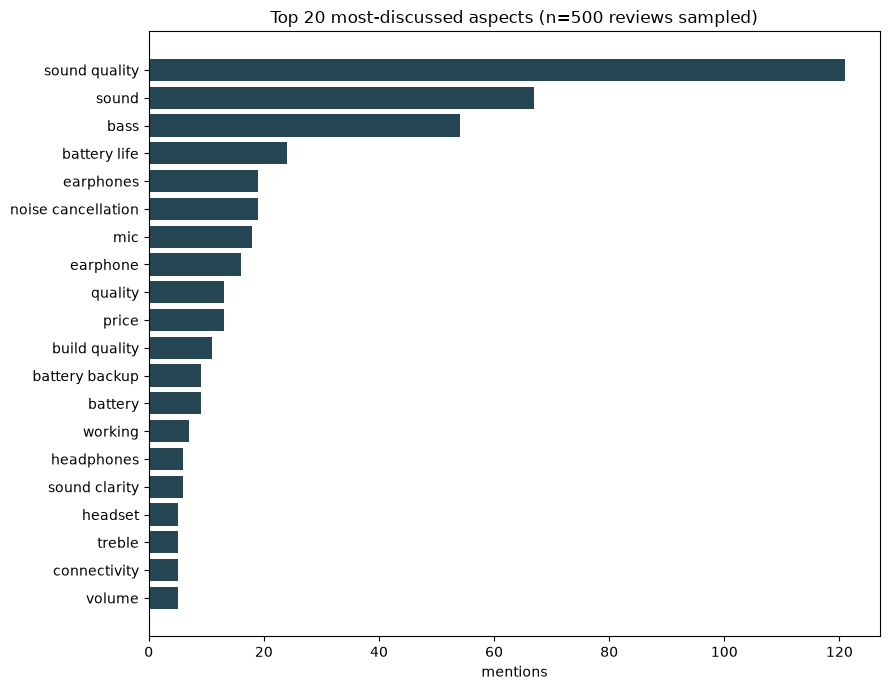

In [9]:
top20 = long_df["aspect_normalized"].value_counts().head(20)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top20.index[::-1], top20.values[::-1], color="#264653")
ax.set_title(f"Top 20 most-discussed aspects (n={len(reviews)} reviews sampled)")
ax.set_xlabel("mentions")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_aspect_frequency.png", dpi=150)
plt.show()


## 9. Chart 2 — Sentiment by aspect ("the money chart", §16.2)

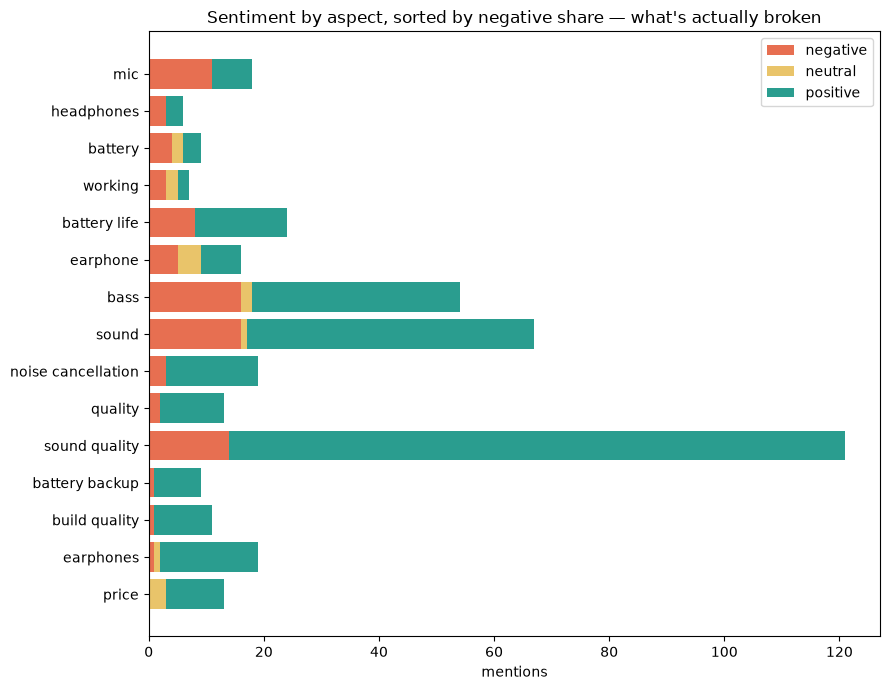

In [10]:
top_aspects_for_sentiment = long_df["aspect_normalized"].value_counts().head(15).index
sentiment_counts = (
    long_df[long_df["aspect_normalized"].isin(top_aspects_for_sentiment)]
    .groupby(["aspect_normalized", "sentiment"]).size().unstack(fill_value=0)
)
for col in ["negative", "neutral", "positive"]:
    if col not in sentiment_counts.columns:
        sentiment_counts[col] = 0
sentiment_counts["neg_share"] = sentiment_counts["negative"] / sentiment_counts.sum(axis=1)
sentiment_counts = sentiment_counts.sort_values("neg_share", ascending=True)

fig, ax = plt.subplots(figsize=(9, 7))
bottom = np.zeros(len(sentiment_counts))
colors = {"negative": "#e76f51", "neutral": "#e9c46a", "positive": "#2a9d8f"}
for sentiment in ["negative", "neutral", "positive"]:
    ax.barh(sentiment_counts.index, sentiment_counts[sentiment], left=bottom,
            color=colors[sentiment], label=sentiment)
    bottom += sentiment_counts[sentiment].values
ax.set_title("Sentiment by aspect, sorted by negative share — what's actually broken")
ax.set_xlabel("mentions")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_sentiment_by_aspect.png", dpi=150)
plt.show()


## 10. Chart 3 — Star rating vs. aspect sentiment (§16.2, closes the §2.1 loop)

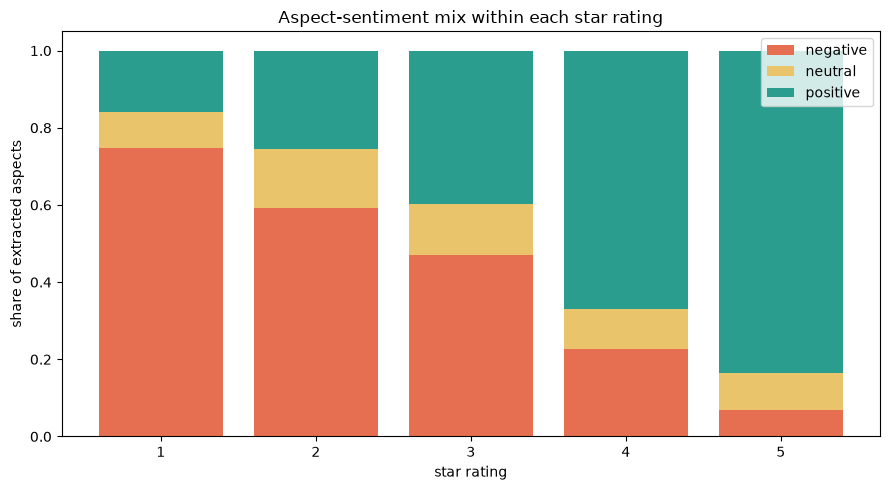

In [11]:
star_sentiment = long_df.groupby(["ReviewStar", "sentiment"]).size().unstack(fill_value=0)
star_sentiment_pct = star_sentiment.div(star_sentiment.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(9, 5))
bottom = np.zeros(len(star_sentiment_pct))
for sentiment in ["negative", "neutral", "positive"]:
    if sentiment not in star_sentiment_pct.columns:
        continue
    ax.bar(star_sentiment_pct.index.astype(str), star_sentiment_pct[sentiment], bottom=bottom,
           color=colors[sentiment], label=sentiment)
    bottom += star_sentiment_pct[sentiment].values
ax.set_title("Aspect-sentiment mix within each star rating")
ax.set_xlabel("star rating")
ax.set_ylabel("share of extracted aspects")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_star_vs_aspect_sentiment.png", dpi=150)
plt.show()


If 3-star reviews show a real mix of positive and negative aspects rather
than a block of uniform "neutral," that's the direct empirical evidence for
this project's opening claim (§2.1) — a single star rating hides
information a star-rating dashboard alone can't recover.


## 11. Chart 4 — Per-product comparison (if volume supports it)

Products with enough extracted aspects for a meaningful breakdown (>=20 rows):
Product
boAt Rockerz 255       311
Sennheiser CX 6.0BT    287
JBL T110BT              58
JBL T205BT              49
Name: count, dtype: int64


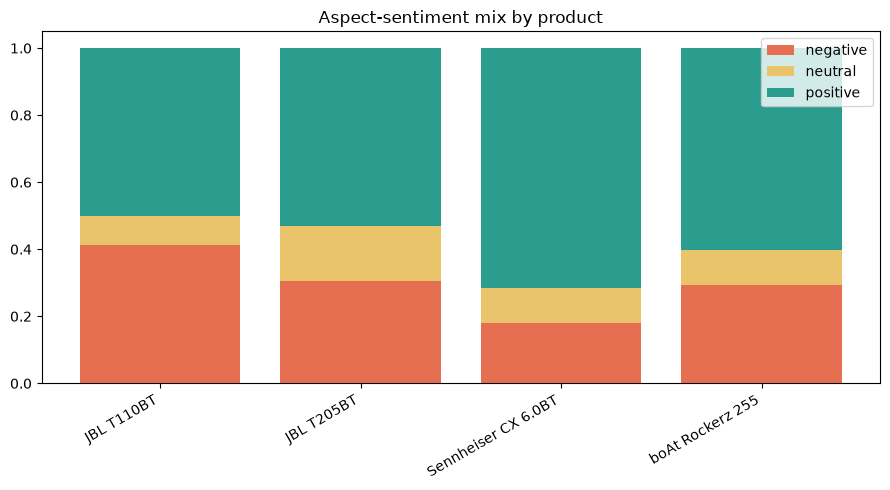

In [12]:
product_counts = long_df["Product"].value_counts()
print("Products with enough extracted aspects for a meaningful breakdown (>=20 rows):")
print(product_counts[product_counts >= 20])

top_products = product_counts[product_counts >= 20].head(8).index
if len(top_products) >= 2:
    sub = long_df[long_df["Product"].isin(top_products)]
    product_sentiment = sub.groupby(["Product", "sentiment"]).size().unstack(fill_value=0)
    product_sentiment_pct = product_sentiment.div(product_sentiment.sum(axis=1), axis=0)

    fig, ax = plt.subplots(figsize=(9, 5))
    bottom = np.zeros(len(product_sentiment_pct))
    for sentiment in ["negative", "neutral", "positive"]:
        if sentiment not in product_sentiment_pct.columns:
            continue
        ax.bar(product_sentiment_pct.index, product_sentiment_pct[sentiment], bottom=bottom,
               color=colors[sentiment], label=sentiment)
        bottom += product_sentiment_pct[sentiment].values
    ax.set_title("Aspect-sentiment mix by product")
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
    ax.legend()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "04_per_product_comparison.png", dpi=150)
    plt.show()
else:
    print(f"\nOnly {len(top_products)} product(s) have >=20 extracted aspects in this "
          f"{SAMPLE_REVIEWS}-review sample — not enough for a meaningful per-product chart. "
          f"Expect this to resolve on the full-corpus run.")


## 12. Manual spot-check — 50 sampled outputs (§16.3), for you to actually read

No gold labels exist on this corpus, so unlike Stage 7's
`error_analysis.csv` this is **not** an automated categorization — just a
plain, readable export. Read it before writing anything about output
quality on this corpus.


In [13]:
rng = np.random.default_rng(SEED)
spot_check_idx = rng.choice(len(raw_generations), size=min(50, len(raw_generations)), replace=False)

spot_check_rows = [raw_generations[i] for i in spot_check_idx]
spot_check_df = pd.DataFrame(spot_check_rows)[["review_id", "sentence_idx", "text", "raw_output"]]
spot_check_df.to_csv(RESULTS_DIR / "application_spot_check_sample.csv", index=False)
print(f"Wrote {RESULTS_DIR / 'application_spot_check_sample.csv'} ({len(spot_check_df)} rows)")
spot_check_df.head(5)


Wrote /home/sreekanth/Downloads/SEM 7/asmta/results/application_spot_check_sample.csv (50 rows)


,review_id,sentence_idx,text,raw_output
0,225,0,Call sound clarity is not good,"{""aspects"":[],""overall"":""neutral""}"
1,274,1,I personally am fan of Sennheiser but this is ...,"{""aspects"":[],""overall"":""neutral""}"
2,245,1,Sound Quality is not good .,"{""aspects"":[],""overall"":""neutral""}"
3,52,0,Awesome sound with bass..I got it for ₹999..Fo...,"{""aspects"":[{""aspect"":""sound"",""sentiment"":""pos..."
4,413,0,Awesome...Good product and good sound but who ...,"{""aspects"":[],""overall"":""neutral""}"


## 13. Zero-shot comparison, on the SAME sentences (added after the fact)

**Why this section exists:** everything above uses only the fine-tuned
model. The only zero-shot-vs-fine-tuned evidence anywhere in this project
lived in `results/results_table.csv`, and only on the SemEval benchmark —
never on this corpus. That leaves the actual business-facing deliverable
one-sided: no way to point at *this* data and show what fine-tuning
changed. This section closes that gap by running the untouched base model
(`mcfg.ACTIVE_MODEL`, zero-shot) over the **identical 1,113 sentences**
already processed above — same inputs, same generation settings, only the
weights differ, which is the same fairness discipline (§10.3) used
everywhere else in this project.

There is no gold data on this corpus, so this can't reuse `src/eval_metrics.py`'s
scoring functions the way the benchmark comparison did (those need gold
aspects). What's measured instead: JSON validity rate, and the *contrast* in
extraction behavior (share of sentences where each model found nothing,
average aspects found per sentence) — real signal, not a proxy for
"correctness."


In [14]:
if not mcfg.model_available(mcfg.ACTIVE_MODEL):
    raise RuntimeError(f"ACTIVE_MODEL '{mcfg.ACTIVE_MODEL}' is not registered locally.")
print(f"Zero-shot model confirmed present: {mcfg.ACTIVE_MODEL}")

zs_raw_generations = []
t_start = time.time()

for i, row in sentences_df.iterrows():
    try:
        resp = mcfg.generate(row["text"], model=mcfg.ACTIVE_MODEL, options=GEN_OPTIONS)
        raw_output = resp.get("response", "")
        error = None
    except Exception as e:
        raw_output = ""
        error = repr(e)

    zs_raw_generations.append({
        "review_id": row["review_id"],
        "sentence_idx": row["sentence_idx"],
        "text": row["text"],
        "raw_output": raw_output,
        "error": error,
    })

    if (i + 1) % 100 == 0 or (i + 1) == len(sentences_df):
        elapsed = time.time() - t_start
        print(f"  {i+1}/{len(sentences_df)} — {elapsed:.0f}s elapsed "
              f"({(i+1)/elapsed:.2f} sentences/sec)")

t_total_zs = time.time() - t_start
n_errors_zs = sum(1 for r in zs_raw_generations if r["error"] is not None)
print(f"\nDone. {len(zs_raw_generations)} zero-shot generations in {t_total_zs:.1f}s "
      f"({len(zs_raw_generations)/t_total_zs:.2f} sentences/sec). {n_errors_zs} call(s) failed outright.")

ZS_RAW_GEN_DIR = ROOT / "outputs" / "raw_generations" / "application_zero_shot"
ZS_RAW_GEN_DIR.mkdir(parents=True, exist_ok=True)
zs_raw_gen_path = ZS_RAW_GEN_DIR / "raw_generations.jsonl"
with open(zs_raw_gen_path, "w") as f:
    for r in zs_raw_generations:
        f.write(json.dumps(r) + "\n")
print(f"Wrote {zs_raw_gen_path}")


Zero-shot model confirmed present: qwen2.5:1.5b-instruct


  100/1113 — 37s elapsed (2.67 sentences/sec)


  200/1113 — 69s elapsed (2.89 sentences/sec)


  300/1113 — 103s elapsed (2.92 sentences/sec)


  400/1113 — 136s elapsed (2.94 sentences/sec)


...

  800/1113 — 271s elapsed (2.96 sentences/sec)


  900/1113 — 300s elapsed (3.00 sentences/sec)


  1000/1113 — 333s elapsed (3.00 sentences/sec)


  1100/1113 — 364s elapsed (3.03 sentences/sec)


  1113/1113 — 369s elapsed (3.02 sentences/sec)

Done. 1113 zero-shot generations in 368.7s (3.02 sentences/sec). 0 call(s) failed outright.
Wrote /home/sreekanth/Downloads/SEM 7/asmta/outputs/raw_generations/application_zero_shot/raw_generations.jsonl


In [15]:
def summarize_generations(records, parser):
    n = len(records)
    n_valid = 0
    n_zero_aspect = 0
    total_aspects = 0
    for r in records:
        parsed = parser(r["raw_output"])
        if parsed is None:
            continue
        n_valid += 1
        n_asp = len(parsed.get("aspects", []))
        total_aspects += n_asp
        if n_asp == 0:
            n_zero_aspect += 1
    return {
        "n": n,
        "validity_rate": n_valid / n if n else 0.0,
        "zero_aspect_share": n_zero_aspect / n_valid if n_valid else 0.0,  # among parseable outputs
        "avg_aspects_per_parseable_sentence": total_aspects / n_valid if n_valid else 0.0,
    }

zs_strict = summarize_generations(zs_raw_generations, em.parse_strict)
zs_lenient = summarize_generations(zs_raw_generations, em.parse_lenient)
ft_strict_app = summarize_generations(raw_generations, em.parse_strict)
ft_lenient_app = summarize_generations(raw_generations, em.parse_lenient)

print("ZERO-SHOT  strict:", zs_strict)
print("ZERO-SHOT lenient:", zs_lenient)
print("FINE-TUNED  strict:", ft_strict_app)
print("FINE-TUNED lenient:", ft_lenient_app)


ZERO-SHOT  strict: {'n': 1113, 'validity_rate': 0.19227313566936208, 'zero_aspect_share': 0.0, 'avg_aspects_per_parseable_sentence': 2.0233644859813085}
ZERO-SHOT lenient: {'n': 1113, 'validity_rate': 0.8921832884097035, 'zero_aspect_share': 0.023162134944612285, 'avg_aspects_per_parseable_sentence': 1.6233635448136958}
FINE-TUNED  strict: {'n': 1113, 'validity_rate': 1.0, 'zero_aspect_share': 0.6460017969451932, 'avg_aspects_per_parseable_sentence': 0.6666666666666666}
FINE-TUNED lenient: {'n': 1113, 'validity_rate': 1.0, 'zero_aspect_share': 0.6460017969451932, 'avg_aspects_per_parseable_sentence': 0.6666666666666666}


## 14. Chart 5 — Fine-tuning's effect, measured on the earphone corpus itself

This is the chart that was missing: not the SemEval benchmark, not a repeat
of the doc's placeholder table — the actual before/after on the real
business-facing data, same 1,113 sentences, same generation settings, only
the weights different.


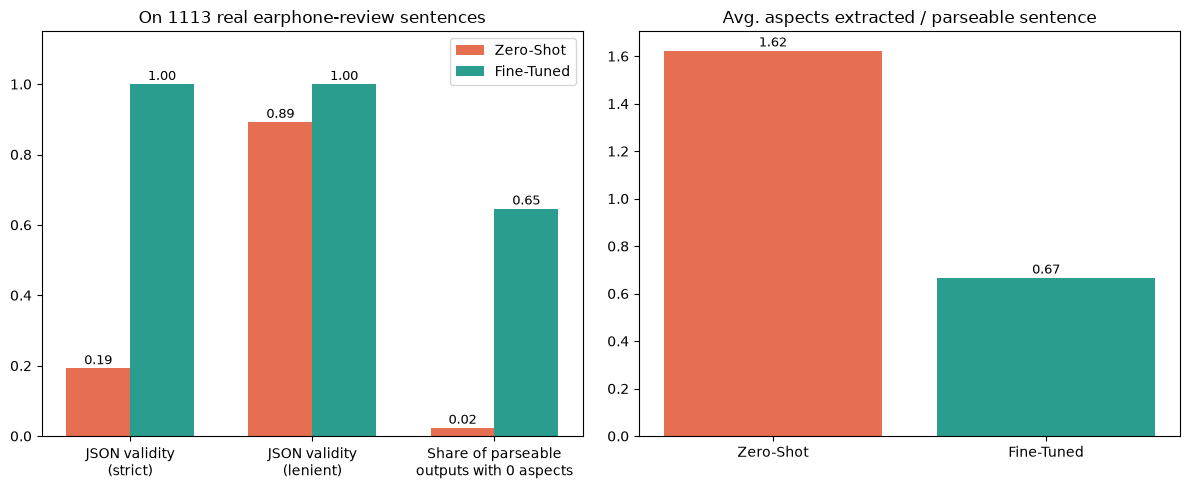

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left: rate-based metrics (0-1 scale)
rate_labels = ["JSON validity\n(strict)", "JSON validity\n(lenient)", "Share of parseable\noutputs with 0 aspects"]
zs_rates = [zs_strict["validity_rate"], zs_lenient["validity_rate"], zs_lenient["zero_aspect_share"]]
ft_rates = [ft_strict_app["validity_rate"], ft_lenient_app["validity_rate"], ft_lenient_app["zero_aspect_share"]]

x = np.arange(len(rate_labels))
width = 0.35
b1 = ax1.bar(x - width / 2, zs_rates, width, label="Zero-Shot", color="#e76f51")
b2 = ax1.bar(x + width / 2, ft_rates, width, label="Fine-Tuned", color="#2a9d8f")
for bars in (b1, b2):
    for b in bars:
        h = b.get_height()
        ax1.annotate(f"{h:.2f}", xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 3),
                     textcoords="offset points", ha="center", fontsize=9)
ax1.set_xticks(x)
ax1.set_xticklabels(rate_labels)
ax1.set_ylim(0, 1.15)
ax1.set_title(f"On {len(sentences_df)} real earphone-review sentences")
ax1.legend()

# Right: average aspects extracted per parseable sentence (different scale)
avg_labels = ["Zero-Shot", "Fine-Tuned"]
avg_vals = [zs_lenient["avg_aspects_per_parseable_sentence"], ft_lenient_app["avg_aspects_per_parseable_sentence"]]
b3 = ax2.bar(avg_labels, avg_vals, color=["#e76f51", "#2a9d8f"])
for b in b3:
    h = b.get_height()
    ax2.annotate(f"{h:.2f}", xy=(b.get_x() + b.get_width() / 2, h), xytext=(0, 3),
                 textcoords="offset points", ha="center", fontsize=9)
ax2.set_title("Avg. aspects extracted / parseable sentence")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_finetuning_effect_on_application_corpus.png", dpi=150)
plt.show()


### Summary

- Ran on a **sample** (fixed seed 42, size set by `SAMPLE_REVIEWS` in
  Section 1), not the full corpus — confirm this cell-by-cell output looks
  sane, then set `SAMPLE_REVIEWS = None` and re-run for the full
  ~14,337-review corpus.
- Real-world JSON validity rate measured directly (Section 6) — compare
  against the 100% strict validity seen on curated SemEval test sentences.
- Four charts saved to `figures/` (or three, if per-product volume was too
  thin at this sample size).
- `results/application_aspect_sentiment.csv` — the full long-format
  extraction table.
- `results/application_spot_check_sample.csv` — 50 examples for manual
  reading. **This step is not optional** — the doc is explicit that a
  program can't substitute for actually reading outputs when judging
  transfer quality onto an unlabeled, out-of-domain corpus.
- **Sections 13-14 (added after the fact):** ran the zero-shot base model
  over the identical sentences already processed, and charted the contrast
  directly — `figures/05_finetuning_effect_on_application_corpus.png`. This
  is the piece that was missing: every chart above used only the fine-tuned
  model, so there was no way to see, on the actual business-facing data,
  what fine-tuning changed. The benchmark comparison
  (`figures/benchmark_zero_shot_vs_finetuned.png`, from `04_evaluate.ipynb`)
  is the rigorous labeled-data evidence; this section is the same question
  answered on data that actually matters for the business case.
